# What is JSON?
JSON (JavaScript Object Notation) is a lightweight, text-based data format used to store and transport data between a server and a web application.

Even though it is derived from JavaScript object syntax, JSON is completely language-independent and can be used with almost any programming language, including Python, Java, C++, and Go

### Simple JSON structure:

{  
  "name": "Alice",  
  "age": 24,  
  "city": "London"  
}   

### JSON can store:

       - objects
       - lists
       - nested values
       - booleans
       - numbers
       - nulls

### for example:

{  
    "user": {  
                "name": "Alice",  
                "age": 24  
            },  
    "skills": ["Python", "SQL", "Machine Learning"],  
    "active": true  
}  

### JSON in Python:
When you read JSON in Python, you usually convert it into normal Python objects.

That means JSON becomes things like:

    - dictionaries
    - lists
    - strings
    - integers
    - floats
    - booleans
    - None

### Working with JSON Data

In [1]:
import json

That module lets you:

    - read JSON files
    - write JSON files
    - convert Python objects into JSON
    - convert JSON into Python objects

### 1. Reading JSON file

In [2]:
with open("user.json", "r", encoding="utf-8") as file:
    data = json.load(file)
print(data)

{'name': 'Alice', 'age': 24, 'city': 'London'}


#### 2. Accessing JSON values

In [3]:
print(data["name"])
print(data["age"])
print(data["city"])

Alice
24
London


#### 3. JSON array becomes Python List


In [4]:
with open("skills.json", "r", encoding="utf-8") as file:
    skills = json.load(file)
print(skills)
print(type(skills))

['Python', 'SQL', 'Machine Learning']
<class 'list'>


That’s important because many API responses are not single objects.

They are often lists of objects.

#### 4. More Realistic JSON data

In [5]:
with open("users.json", "r", encoding="utf-8") as file:
    users = json.load(file)
for user in users:
    print(f"{user['name']} is {user['age']} years old.")

Alice is 24 years old.
Bob is 29 years old.
Charlie is 31 years old.


#### 5. Nested JSON

Consider a user profile data

In [7]:
with open("profile.json", "r", encoding="utf-8") as file:
    profile = json.load(file)
print(profile["user"]["name"])
print(profile["user"]["location"]["city"])
print(profile["active"])

Alice
London
True


modern data is often nested, not flat.

#### 6. Safley handling missing JSON key

A common beginner mistake is assuming every field will always exist.

Bad assumption.

Real JSON data often has optional or missing fields.

In [8]:
print(profile["user"]["phone"])

KeyError: 'phone'

If "phone" doesn’t exist, that raises a KeyError.

In [9]:
# safer

print(profile["user"].get("phone", "Not provided"))

Not provided


Why this matters
Because real API or event data is often incomplete.

And if your code crashes every time one optional field is missing, your pipeline becomes fragile very quickly.

#### 7. Writing JSON file in Python

Now let’s go the other direction.

Suppose you have Python data and want to save it as JSON.

In [11]:
user = {
    "name": "Alice",
    "age": 24,
    "city": "London"
}
with open("output_user.json", "w", encoding="utf-8") as file:
    json.dump(user, file)

#### 8. A realistic mini example - list of products

In [ ]:
[
  {"product": "Laptop", "rating": 5, "verified": true},
  {"product": "Keyboard", "rating": 4, "verified": false},
  {"product": "Mouse", "rating": 5, "verified": true}
]

You want to:

    - read the file
    - keep only verified reviews
    - save them to a new JSON file

In [15]:
with open("reviews.json", "r", encoding="utf-8") as file:
    reviews = json.load(file)
verified_reviews = []
for review in reviews:
    if review.get("verified") is True:
        verified_reviews.append(review)
with open("verified_reviews.json", "w", encoding="utf-8") as file:
    json.dump(verified_reviews, file, indent=4)
print("Verified reviews saved successfully.")

Verified reviews saved successfully.


## Working with API data

https://open-meteo.com/en/docs

#### API call

https://api.open-meteo.com/v1/forecast?latitude=24.8607&longitude=67.0011&current=temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m

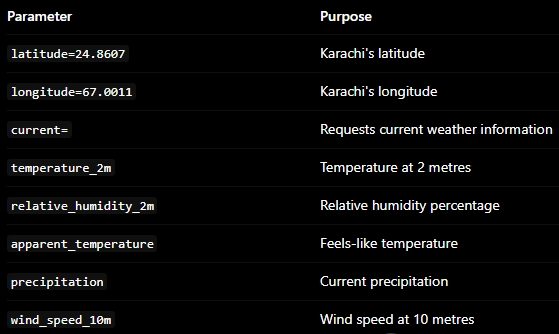

In [18]:
import requests

url = "https://api.open-meteo.com/v1/forecast"

params = {
    "latitude": 24.8607,
    "longitude": 67.0011,
    "current": "temperature_2m,relative_humidity_2m,wind_speed_10m"
}

response = requests.get(url, params=params)

print(response)

<Response [200]>


In [19]:
print(response.text)

{"latitude":24.850615,"longitude":66.992485,"generationtime_ms":0.07176399230957031,"utc_offset_seconds":0,"timezone":"GMT","timezone_abbreviation":"GMT","elevation":7.0,"current_units":{"time":"iso8601","interval":"seconds","temperature_2m":"°C","relative_humidity_2m":"%","wind_speed_10m":"km/h"},"current":{"time":"2026-10-09T10:45","interval":900,"temperature_2m":30.3,"relative_humidity_2m":61,"wind_speed_10m":19.3}}


In [20]:
# converting JSON data to Python Disctionary (deserialization)
data = response.json()

print(data)
print(type(data))

{'latitude': 24.850615, 'longitude': 66.992485, 'generationtime_ms': 0.07176399230957031, 'utc_offset_seconds': 0, 'timezone': 'GMT', 'timezone_abbreviation': 'GMT', 'elevation': 7.0, 'current_units': {'time': 'iso8601', 'interval': 'seconds', 'temperature_2m': '°C', 'relative_humidity_2m': '%', 'wind_speed_10m': 'km/h'}, 'current': {'time': '2026-10-09T10:45', 'interval': 900, 'temperature_2m': 30.3, 'relative_humidity_2m': 61, 'wind_speed_10m': 19.3}}
<class 'dict'>


Notice that current is a dictionary inside another dictionary.

We can access the data using Python dictionary keys:

In [21]:
print(data["latitude"])
print(data["longitude"])
print(data["current"])

24.850615
66.992485
{'time': '2026-10-09T10:45', 'interval': 900, 'temperature_2m': 30.3, 'relative_humidity_2m': 61, 'wind_speed_10m': 19.3}


In [22]:
# to access temperature

print(data["current"]["temperature_2m"])

30.3


In [23]:
# to access humidity

print(data["current"]["relative_humidity_2m"])

61


#### Extract and display specific weather information

In [25]:
url = "https://api.open-meteo.com/v1/forecast"

params = {
    "latitude": 24.8607,
    "longitude": 67.0011,
    "current": (
        "temperature_2m,"
        "relative_humidity_2m,"
        "apparent_temperature,"
        "precipitation,"
        "wind_speed_10m"
    )
}

response = requests.get(url, params=params)
data = response.json()
print(data)

{'latitude': 24.850615, 'longitude': 66.992485, 'generationtime_ms': 0.11670589447021484, 'utc_offset_seconds': 0, 'timezone': 'GMT', 'timezone_abbreviation': 'GMT', 'elevation': 7.0, 'current_units': {'time': 'iso8601', 'interval': 'seconds', 'temperature_2m': '°C', 'relative_humidity_2m': '%', 'apparent_temperature': '°C', 'precipitation': 'mm', 'wind_speed_10m': 'km/h'}, 'current': {'time': '2026-10-09T10:45', 'interval': 900, 'temperature_2m': 30.3, 'relative_humidity_2m': 61, 'apparent_temperature': 32.4, 'precipitation': 0.0, 'wind_speed_10m': 19.3}}


In [26]:
current = data["current"]

temperature = current["temperature_2m"]
humidity = current["relative_humidity_2m"]
feels_like = current["apparent_temperature"]
precipitation = current["precipitation"]
wind_speed = current["wind_speed_10m"]

print("Weather Report: Karachi")
print("------------------------")
print(f"Temperature: {temperature} °C")
print(f"Feels Like: {feels_like} °C")
print(f"Humidity: {humidity}%")
print(f"Precipitation: {precipitation} mm")
print(f"Wind Speed: {wind_speed} km/h")
print(f"Updated at: {current['time']}")

Weather Report: Karachi
------------------------
Temperature: 30.3 °C
Feels Like: 32.4 °C
Humidity: 61%
Precipitation: 0.0 mm
Wind Speed: 19.3 km/h
Updated at: 2026-10-09T10:45


#### Handling API Errors

In [28]:
url = "https://api.open-meteo.com/v1/forecast"

params = {
    "latitude": 24.8607,
    "longitude": 67.0011,
    "current": "temperature_2m,relative_humidity_2m"
}

try:
    response = requests.get(url, params=params, timeout=10)
    response.raise_for_status()   # Raises an exception for unsuccessful HTTP status codes

    data = response.json()

    print("Temperature:", data["current"]["temperature_2m"], "°C")
    print("Humidity:", data["current"]["relative_humidity_2m"], "%")

except requests.exceptions.RequestException as error:
    print("API request failed:", error)

except ValueError as error:
    print("Unable to parse JSON:", error)

except KeyError as error:
    print("Expected weather data is missing:", error)

Temperature: 30.2 °C
Humidity: 62 %


#### Getting weather of any city

So far, we have used Karachi's coordinates. To support any city, we first need to convert a city name into coordinates using the Open-Meteo Geocoding API.

The process is:

Send the city name to the geocoding API.

Extract the latitude and longitude from the JSON response.

Use those coordinates to request weather data.

Extract and display the weather information.

In [30]:
def get_weather(city):
    try:
        # Step 1: Search for the city
        geo_url = "https://geocoding-api.open-meteo.com/v1/search"

        geo_params = {
            "name": city,
            "count": 1,
            "language": "en",
            "format": "json"
        }

        geo_response = requests.get(
            geo_url, params=geo_params, timeout=10
        )
        geo_response.raise_for_status()

        geo_data = geo_response.json()

        # Step 2: Check whether the city exists
        if not geo_data.get("results"):
            print("City not found.")
            return

        place = geo_data["results"][0]

        latitude = place["latitude"]
        longitude = place["longitude"]
        city_name = place["name"]
        country = place.get("country", "Unknown")

        # Step 3: Request weather data
        weather_url = "https://api.open-meteo.com/v1/forecast"

        weather_params = {
            "latitude": latitude,
            "longitude": longitude,
            "current": (
                "temperature_2m,"
                "relative_humidity_2m,"
                "apparent_temperature,"
                "wind_speed_10m"
            )
        }

        weather_response = requests.get(
            weather_url, params=weather_params, timeout=10
        )
        weather_response.raise_for_status()

        weather_data = weather_response.json()

        # Step 4: Extract JSON values
        current = weather_data["current"]

        print(f"\nWeather Report: {city_name}, {country}")
        print("-" * 35)
        print(f"Temperature: {current['temperature_2m']} °C")
        print(f"Feels Like: {current['apparent_temperature']} °C")
        print(f"Humidity: {current['relative_humidity_2m']}%")
        print(f"Wind Speed: {current['wind_speed_10m']} km/h")
        print(f"Updated at: {current['time']}")

    except requests.exceptions.RequestException as error:
        print("Request failed:", error)

    except (ValueError, KeyError) as error:
        print("Unable to process weather data:", error)


city = input("Enter city name: ")
get_weather(city)

Enter city name:  Landon



Weather Report: Landön, Sweden
-----------------------------------
Temperature: 5.6 °C
Feels Like: 1.8 °C
Humidity: 61%
Wind Speed: 10.8 km/h
Updated at: 2026-10-09T11:00
